In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import re
import neptune
import pingouin as pg

import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.stats import pearsonr

In [2]:
ea_datapath = "../data/responses/emotional affect analysis - HumanExpert1.csv"
vi_datapath_2 = "../data/responses/emotional affect analysis - HumanExpert2.csv"
ea_datapath_3 = "../data/responses/emotional affect analysis - HumanExpert3.csv"
ea_datapath_ai_pos = "../data/reporting/positive_emotional_assesed.csv"
ea_datapath_ai_neg = "../data/reporting/negative_emotional_assesed.csv"


ea_data = pd.read_csv(ea_datapath)
ea_data_2 = pd.read_csv(vi_datapath_2)
ea_data_3 = pd.read_csv(ea_datapath_3)
ea_data_ai_pos = pd.read_csv(ea_datapath_ai_pos)
ea_data_ai_neg = pd.read_csv(ea_datapath_ai_neg)

In [6]:
ea_neg_datapath_ai_hum1 = "../data/reporting/model_as_psych_test/n_ea_o4mini_Ania.csv"
ea_neg_datapath_ai_hum2 = "../data/reporting/model_as_psych_test/n_ea_o4mini_Marysia.csv"
ea_neg_datapath_ai_hum3 = "../data/reporting/model_as_psych_test/n_ea_o4mini_Maria.csv"
ea_pos_datapath_ai_hum1 = "../data/reporting/model_as_psych_test/p_ea_o4mini_Ania.csv"
ea_pos_datapath_ai_hum2 = "../data/reporting/model_as_psych_test/p_ea_o4mini_Marysia.csv"
ea_pos_datapath_ai_hum3 = "../data/reporting/model_as_psych_test/p_ea_o4mini_Maria.csv"

ea_neg_data_ai_hum1 = pd.read_csv(ea_neg_datapath_ai_hum1)
ea_neg_data_ai_hum2 = pd.read_csv(ea_neg_datapath_ai_hum2)
ea_neg_data_ai_hum3 = pd.read_csv(ea_neg_datapath_ai_hum3)
ea_pos_data_ai_hum1 = pd.read_csv(ea_pos_datapath_ai_hum1)
ea_pos_data_ai_hum2 = pd.read_csv(ea_pos_datapath_ai_hum2)
ea_pos_data_ai_hum3 = pd.read_csv(ea_pos_datapath_ai_hum3)


In [7]:
mapping_pos = {
    "Prompt violating policy": np.nan,
    "Extremely high intensity of positive emotional affect": 5,
    "High intensity of positive emotional affect": 4,
    "Average intensity of positive emotional affect": 3,
    "Low intensity of positive emotional affect": 2,
    "Extremely low intensity of positive emotional affect": 1
}
mapping_neg = {
    "Prompt violating policy": np.nan,
    "Extremely high intensity of negative emotional affect": 5,
    "High intensity of negative emotional affect": 4,
    "Average intensity of negative emotional affect": 3,
    "Low intensity of negative emotional affect": 2,
    "Extremely low intensity of negative emotional affect": 1
}
ea_data["positive_numeric_hum_1"] = ea_data["Positive Assessment:"].map(mapping_pos)
ea_data["negative_numeric_hum_1"] = ea_data["Negative Assessment:"].map(mapping_neg)
ea_data_2["positive_numeric_hum_2"] = ea_data_2["Positive Assessment:"].map(mapping_pos)
ea_data_2["negative_numeric_hum_2"] = ea_data_2["Negative Assessment:"].map(mapping_neg)
ea_data_3["positive_numeric_hum_3"] = ea_data_3["Positive Assessment:"].map(mapping_pos)
ea_data_3["negative_numeric_hum_3"] = ea_data_3["Negative Assessment:"].map(mapping_neg)
ea_data_ai_pos["positive_numeric_ai"] = ea_data_ai_pos["score"].map(mapping_pos)
ea_data_ai_neg["negative_numeric_ai"] = ea_data_ai_neg["score"].map(mapping_neg)


In [8]:
ea_neg_data_ai_hum1["negative_numeric_ai_hum_1"] = ea_neg_data_ai_hum1["score"].map(mapping_neg)
ea_neg_data_ai_hum2["negative_numeric_ai_hum_2"] = ea_neg_data_ai_hum2["score"].map(mapping_neg)
ea_neg_data_ai_hum3["negative_numeric_ai_hum_3"] = ea_neg_data_ai_hum3["score"].map(mapping_neg)
ea_pos_data_ai_hum1["positive_numeric_ai_hum_1"] = ea_pos_data_ai_hum1["score"].map(mapping_pos)
ea_pos_data_ai_hum2["positive_numeric_ai_hum_2"] = ea_pos_data_ai_hum2["score"].map(mapping_pos)
ea_pos_data_ai_hum3["positive_numeric_ai_hum_3"] = ea_pos_data_ai_hum3["score"].map(mapping_pos)

In [9]:
# rename the columns
ea_data = ea_data.rename(columns={"Post:": "post"})
ea_data_2 = ea_data_2.rename(columns={"Post:": "post"})
ea_data_3 = ea_data_3.rename(columns={"Post:": "post"})

ea_data_ai_neg = ea_data_ai_neg.rename(columns={"reason": "reason_neg"})
ea_data_ai_pos = ea_data_ai_pos.rename(columns={"reason": "reason_pos"})


# Drop the assessment columns
ea_data = ea_data.drop(columns=["Positive Assessment:"])
ea_data = ea_data.drop(columns=["Negative Assessment:"])
ea_data_2 = ea_data_2.drop(columns=["Positive Assessment:"])
ea_data_2 = ea_data_2.drop(columns=["Negative Assessment:"])
ea_data_3 = ea_data_3.drop(columns=["Positive Assessment:"])
ea_data_3 = ea_data_3.drop(columns=["Negative Assessment:"])
ea_data_ai_pos = ea_data_ai_pos.drop(columns=["score"])
ea_data_ai_neg = ea_data_ai_neg.drop(columns=["score"])


In [10]:
# drop the reason columns and score columns from AI human assessments

ea_neg_data_ai_hum1 = ea_neg_data_ai_hum1.drop(columns=["reason", "score"])
ea_neg_data_ai_hum2 = ea_neg_data_ai_hum2.drop(columns=["reason", "score"])
ea_neg_data_ai_hum3 = ea_neg_data_ai_hum3.drop(columns=["reason", "score"])
ea_pos_data_ai_hum1 = ea_pos_data_ai_hum1.drop(columns=["reason", "score"])
ea_pos_data_ai_hum2 = ea_pos_data_ai_hum2.drop(columns=["reason", "score"])
ea_pos_data_ai_hum3 = ea_pos_data_ai_hum3.drop(columns=["reason", "score"])


In [11]:
# join the dataframes
data = pd.merge(ea_data, ea_data_2, on="post", how="inner")
data = pd.merge(data, ea_data_3, on="post", how="inner")
data = pd.merge(data, ea_data_ai_pos, on="post", how="inner")
data = pd.merge(data, ea_data_ai_neg, on="post", how="inner")

# calculate the mean of the positive and negative assessments
data["positive_mean"] = data[["positive_numeric_hum_1", "positive_numeric_hum_2", "positive_numeric_hum_3"]].mean(axis=1)
data["negative_mean"] = data[["negative_numeric_hum_1", "negative_numeric_hum_2", "negative_numeric_hum_3"]].mean(axis=1)


In [12]:
# join the dataframes with the AI assessments
data = pd.merge(data, ea_neg_data_ai_hum1, on="post", how="inner")
data = pd.merge(data, ea_neg_data_ai_hum2, on="post", how="inner")
data = pd.merge(data, ea_neg_data_ai_hum3, on="post", how="inner")
data = pd.merge(data, ea_pos_data_ai_hum1, on="post", how="inner")
data = pd.merge(data, ea_pos_data_ai_hum2, on="post", how="inner")
data = pd.merge(data, ea_pos_data_ai_hum3, on="post", how="inner")
# calculate the mean of the positive and negative assessments for AI
data["positive_mean_ai"] = data[["positive_numeric_ai_hum_1", "positive_numeric_ai_hum_2", "positive_numeric_ai_hum_3"]].mean(axis=1)
data["negative_mean_ai"] = data[["negative_numeric_ai_hum_1", "negative_numeric_ai_hum_2", "negative_numeric_ai_hum_3"]].mean(axis=1)


In [13]:
data.head()

,post,positive_numeric_hum_1,negative_numeric_hum_1,positive_numeric_hum_2,negative_numeric_hum_2,positive_numeric_hum_3,negative_numeric_hum_3,reason_pos,positive_numeric_ai,reason_neg,...,positive_mean,negative_mean,negative_numeric_ai_hum_1,negative_numeric_ai_hum_2,negative_numeric_ai_hum_3,positive_numeric_ai_hum_1,positive_numeric_ai_hum_2,positive_numeric_ai_hum_3,positive_mean_ai,negative_mean_ai
0,As you all know I don't like to travel. But I ...,3.0,3.0,3.0,3.0,3.0,2.0,The author exhibits determination and a proac...,4.0,The statement reflects a mild dislike of trav...,...,3.000000,2.666667,1.0,2.0,4.0,3.0,4.0,2.0,3.000000,2.333333
1,I went to Dún Laoghaire and it was lovely,4.0,2.0,4.0,1.0,3.0,2.0,The statement expresses clear positive emotio...,4.0,"The statement conveys a positive experience, ...",...,3.666667,1.666667,1.0,1.0,1.0,4.0,4.0,3.0,3.666667,1.000000
2,Imagine strolling along the sandy shores of th...,5.0,2.0,4.0,1.0,5.0,1.0,The text is rich with vivid and uplifting ima...,5.0,The text vividly describes a peaceful and idy...,...,4.666667,1.333333,1.0,1.0,1.0,5.0,5.0,5.0,5.000000,1.000000
3,just returned from an unforgettable trip to Ky...,3.0,2.0,4.0,1.0,5.0,1.0,The text is rich with enthusiastic and positi...,5.0,The text predominantly conveys positive emoti...,...,4.000000,1.333333,1.0,1.0,1.0,5.0,5.0,5.0,5.000000,1.000000
4,"I traveled to Tokyo for leisure and fun, i boo...",2.0,3.0,4.0,2.0,3.0,2.0,The text conveys a strong sense of enjoyment ...,4.0,The text primarily expresses positive emotion...,...,3.000000,2.333333,1.0,1.0,1.0,4.0,5.0,5.0,4.666667,1.000000


In [14]:
data.notnull().sum()

post                         116
positive_numeric_hum_1       116
negative_numeric_hum_1       116
positive_numeric_hum_2       116
negative_numeric_hum_2       116
positive_numeric_hum_3       116
negative_numeric_hum_3       116
reason_pos                   116
positive_numeric_ai          116
reason_neg                   116
negative_numeric_ai          116
positive_mean                116
negative_mean                116
negative_numeric_ai_hum_1    116
negative_numeric_ai_hum_2    116
negative_numeric_ai_hum_3    116
positive_numeric_ai_hum_1    116
positive_numeric_ai_hum_2    116
positive_numeric_ai_hum_3    116
positive_mean_ai             116
negative_mean_ai             116
dtype: int64

In [15]:
# drop the columns that have 0 in ai_assessment
data = data.dropna(subset=["positive_numeric_ai", "negative_numeric_ai"])

In [16]:
data.shape

(116, 21)

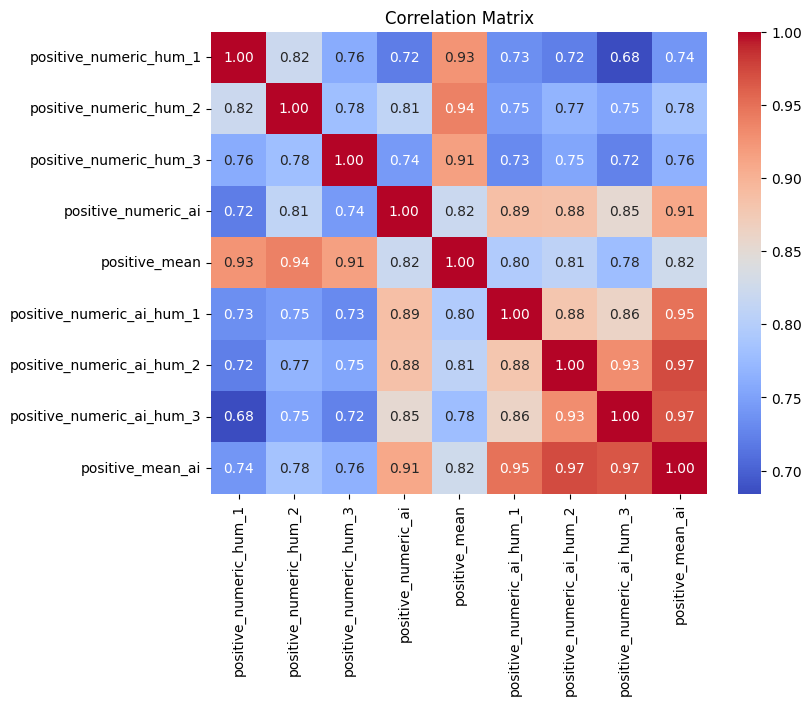

In [17]:
# select only columns that have pos in their name
df_num_pos = data.filter(regex="pos").select_dtypes(include=["number"])

corr=df_num_pos.corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

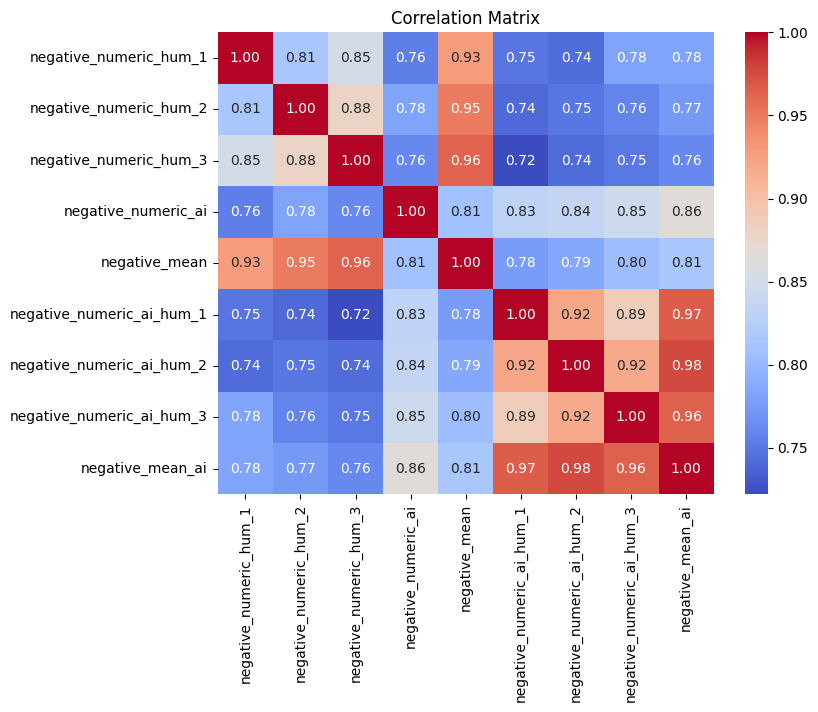

In [18]:
# select only columns that have pos in their name
df_num_neg = data.filter(regex="neg").select_dtypes(include=["number"])

corr=df_num_neg.corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

# Procentages of responses

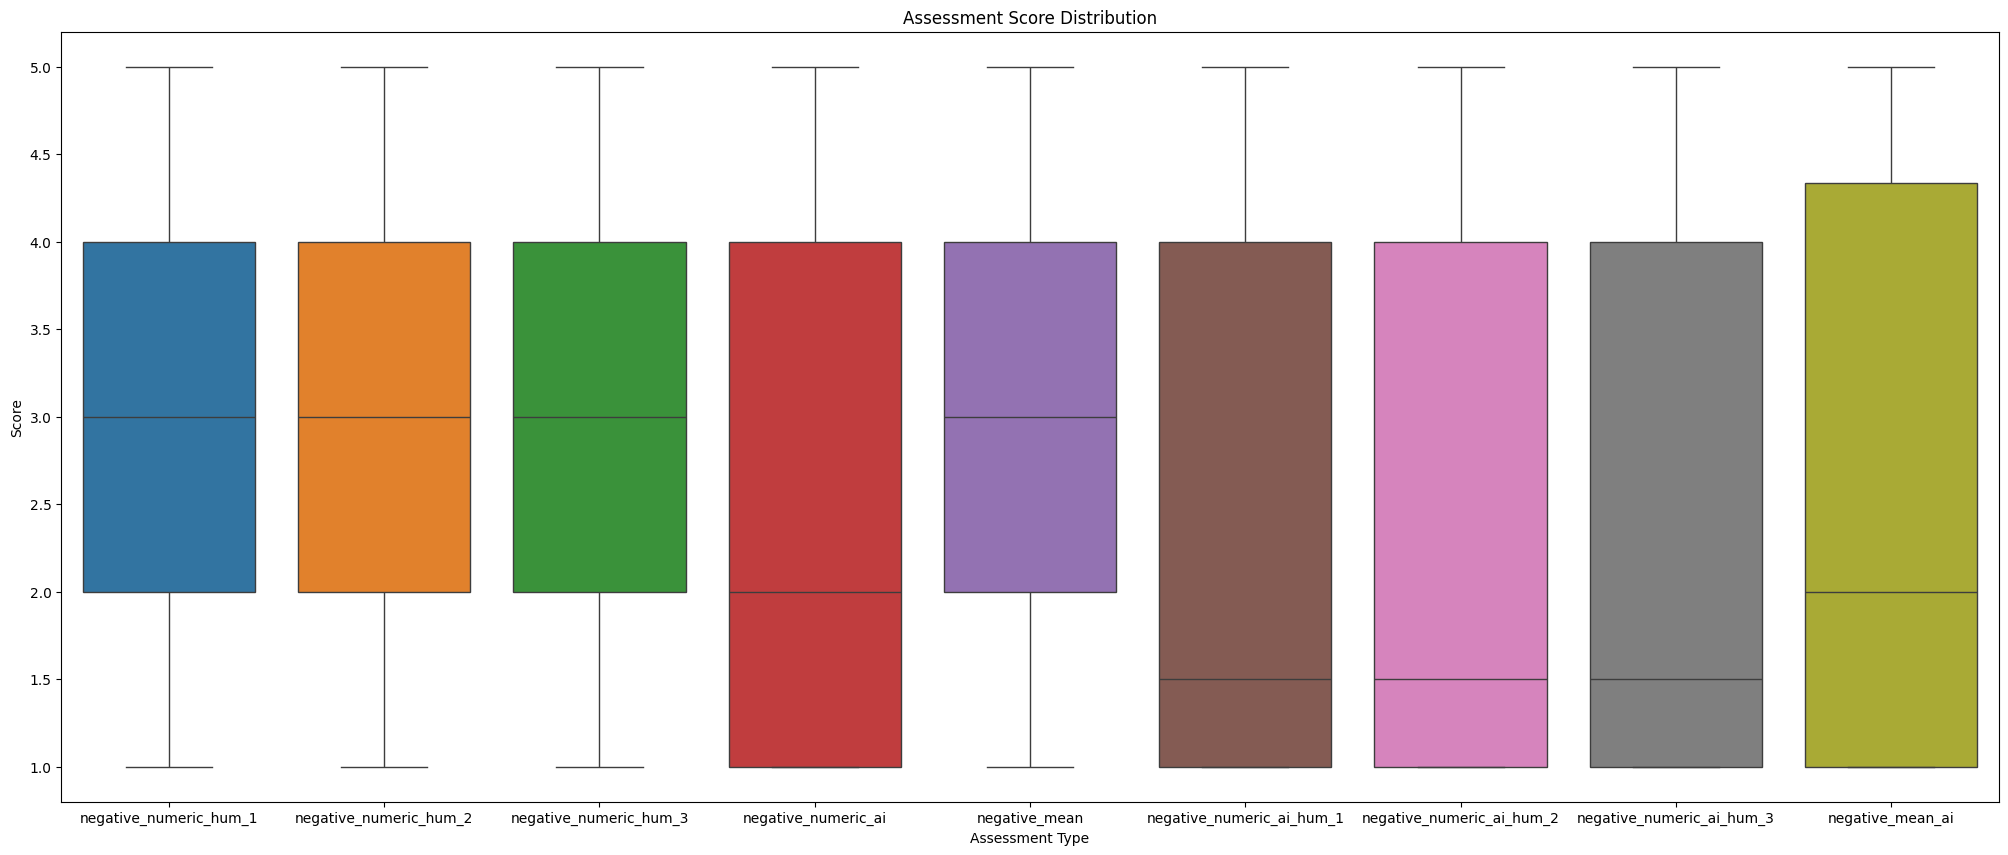

In [19]:
plt.figure(figsize=(25, 10))
sns.boxplot(data=df_num_neg)
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

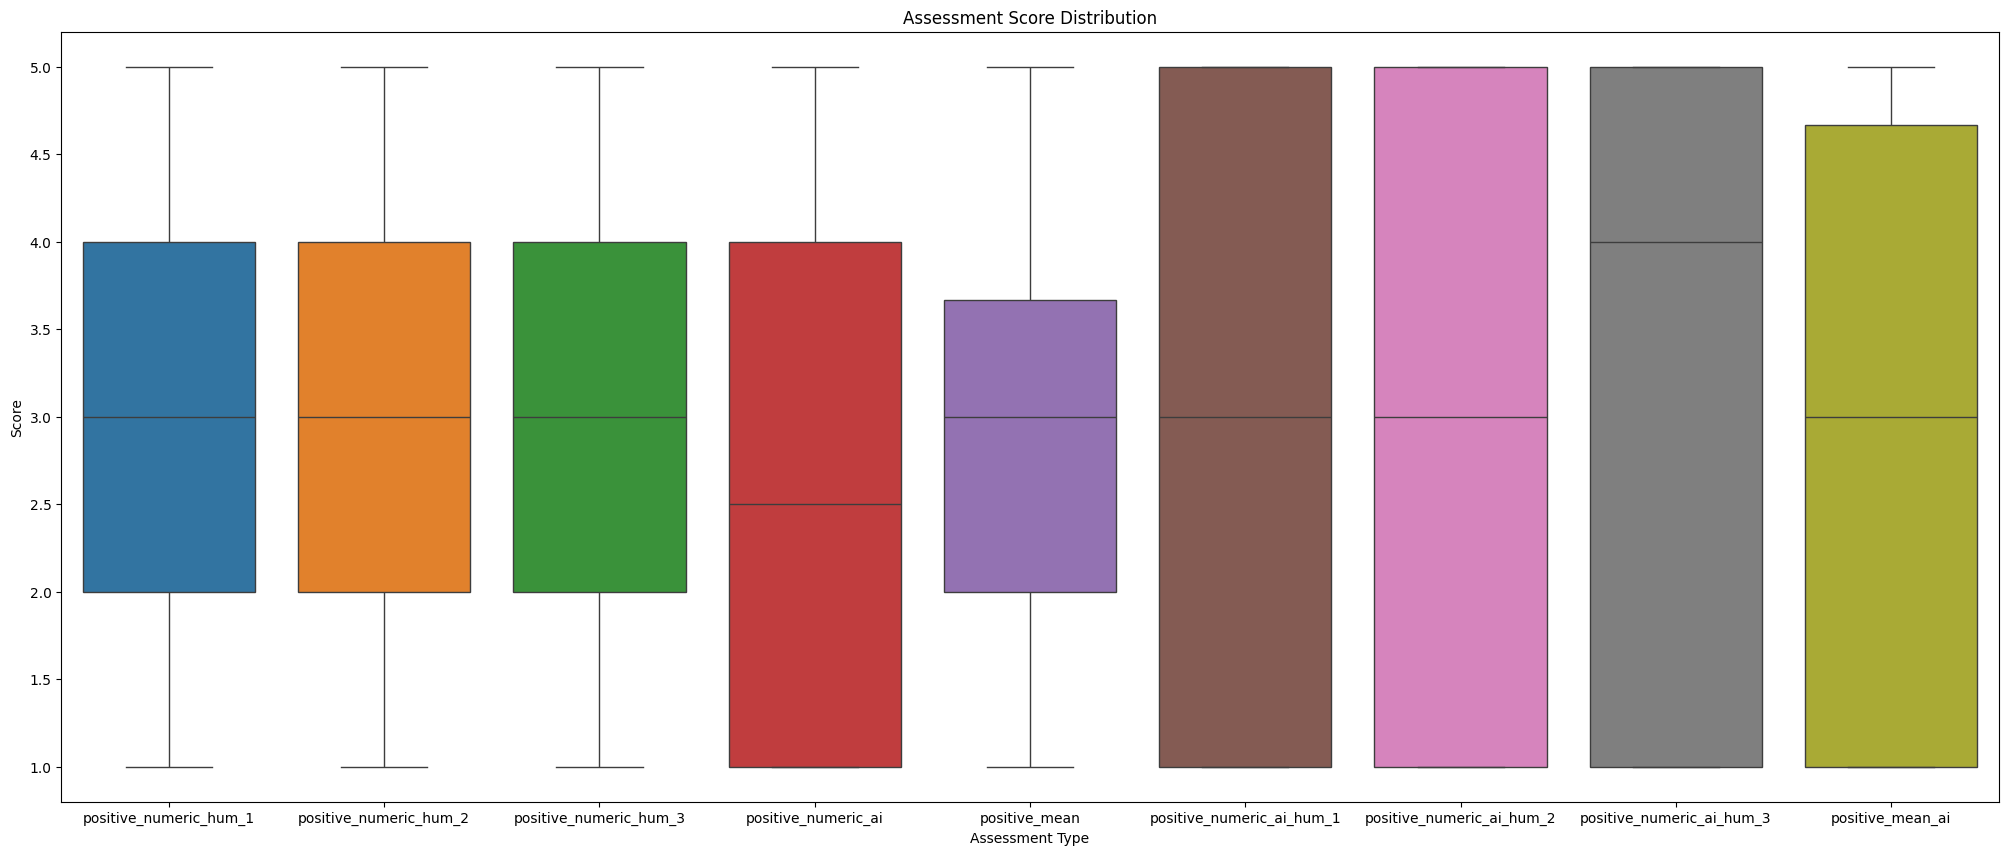

In [20]:
plt.figure(figsize=(25, 10))
sns.boxplot(data=df_num_pos)
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

# Comparison cd.

In [21]:
# Calculate Kendall’s W
# pg.pairwise_corr(data, method="kendall", columns=["human_assessment_1",
#                                                   "human_assessment_2",
#                                                   "human_assessment_3", 
#                                                   "ai_assessment_ex", 
#                                                   "ai_assessment_norm", 
#                                                   "ai_assessment_03"], 
#                                                   padjust="holm")

In [22]:
data.head()

,post,positive_numeric_hum_1,negative_numeric_hum_1,positive_numeric_hum_2,negative_numeric_hum_2,positive_numeric_hum_3,negative_numeric_hum_3,reason_pos,positive_numeric_ai,reason_neg,...,positive_mean,negative_mean,negative_numeric_ai_hum_1,negative_numeric_ai_hum_2,negative_numeric_ai_hum_3,positive_numeric_ai_hum_1,positive_numeric_ai_hum_2,positive_numeric_ai_hum_3,positive_mean_ai,negative_mean_ai
0,As you all know I don't like to travel. But I ...,3.0,3.0,3.0,3.0,3.0,2.0,The author exhibits determination and a proac...,4.0,The statement reflects a mild dislike of trav...,...,3.000000,2.666667,1.0,2.0,4.0,3.0,4.0,2.0,3.000000,2.333333
1,I went to Dún Laoghaire and it was lovely,4.0,2.0,4.0,1.0,3.0,2.0,The statement expresses clear positive emotio...,4.0,"The statement conveys a positive experience, ...",...,3.666667,1.666667,1.0,1.0,1.0,4.0,4.0,3.0,3.666667,1.000000
2,Imagine strolling along the sandy shores of th...,5.0,2.0,4.0,1.0,5.0,1.0,The text is rich with vivid and uplifting ima...,5.0,The text vividly describes a peaceful and idy...,...,4.666667,1.333333,1.0,1.0,1.0,5.0,5.0,5.0,5.000000,1.000000
3,just returned from an unforgettable trip to Ky...,3.0,2.0,4.0,1.0,5.0,1.0,The text is rich with enthusiastic and positi...,5.0,The text predominantly conveys positive emoti...,...,4.000000,1.333333,1.0,1.0,1.0,5.0,5.0,5.0,5.000000,1.000000
4,"I traveled to Tokyo for leisure and fun, i boo...",2.0,3.0,4.0,2.0,3.0,2.0,The text conveys a strong sense of enjoyment ...,4.0,The text primarily expresses positive emotion...,...,3.000000,2.333333,1.0,1.0,1.0,4.0,5.0,5.0,4.666667,1.000000


In [23]:
# Change all raters [human_assessment_1, human_assessment_2, human_assessment_3] to one column
df_long_pos = data.melt(
                  id_vars=['post'],        # columns to keep (not unpivot)
                  value_vars=["positive_numeric_hum_1", "positive_numeric_hum_2", "positive_numeric_hum_3"])

df_long_neg = data.melt(
                id_vars=['post'],        # columns to keep (not unpivot)
                value_vars=["negative_numeric_hum_1", "negative_numeric_hum_2", "negative_numeric_hum_3"])

# df_long_pos_ai = data.melt(
#                   id_vars=['post'],        # columns to keep (not unpivot)
#                   value_vars=["positive_numeric_hum_1", "positive_numeric_hum_2", "positive_numeric_hum_3", "positive_numeric_ai"])

# df_long_neg_ai = data.melt(
#                 id_vars=['post'],        # columns to keep (not unpivot)
#                 value_vars=["negative_numeric_hum_1", "negative_numeric_hum_2", "negative_numeric_hum_3", "negative_numeric_ai"])


df_long_pos_ai = data.melt(
                    id_vars=['post'],        # columns to keep (not unpivot)
                    value_vars=["positive_numeric_ai_hum_1", "positive_numeric_ai_hum_2", "positive_numeric_ai_hum_3"])

df_long_neg_ai = data.melt(
                    id_vars=['post'],        # columns to keep (not unpivot)
                    value_vars=["negative_numeric_ai_hum_1", "negative_numeric_ai_hum_2", "negative_numeric_ai_hum_3"])

In [24]:
pg.intraclass_corr(df_long_pos, targets="post", raters="variable", ratings="value")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.777733,11.497300,115,232,2.768133e-54,"[0.71, 0.83]"
1,ICC2,Single random raters,0.778380,11.968366,115,230,1.541569e-55,"[0.71, 0.83]"
2,ICC3,Single fixed raters,0.785229,11.968366,115,230,1.541569e-55,"[0.72, 0.84]"
3,ICC1k,Average raters absolute,0.913023,11.497300,115,232,2.768133e-54,"[0.88, 0.94]"
4,ICC2k,Average random raters,0.913320,11.968366,115,230,1.541569e-55,"[0.88, 0.94]"
5,ICC3k,Average fixed raters,0.916446,11.968366,115,230,1.541569e-55,"[0.89, 0.94]"


In [25]:
pg.intraclass_corr(df_long_pos_ai, targets="post", raters="variable", ratings="value").round(4)

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.8901,25.3092,115,232,0.0,"[0.85, 0.92]"
1,ICC2,Single random raters,0.8901,25.3240,115,230,0.0,"[0.85, 0.92]"
2,ICC3,Single fixed raters,0.8902,25.3240,115,230,0.0,"[0.85, 0.92]"
3,ICC1k,Average raters absolute,0.9605,25.3092,115,232,0.0,"[0.95, 0.97]"
4,ICC2k,Average random raters,0.9605,25.3240,115,230,0.0,"[0.95, 0.97]"
5,ICC3k,Average fixed raters,0.9605,25.3240,115,230,0.0,"[0.95, 0.97]"


In [26]:
pg.intraclass_corr(df_long_neg, targets="post", raters="variable", ratings="value").round(4)

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.8397,16.7136,115,232,0.0,"[0.79, 0.88]"
1,ICC2,Single random raters,0.8397,16.6865,115,230,0.0,"[0.79, 0.88]"
2,ICC3,Single fixed raters,0.8395,16.6865,115,230,0.0,"[0.79, 0.88]"
3,ICC1k,Average raters absolute,0.9402,16.7136,115,232,0.0,"[0.92, 0.96]"
4,ICC2k,Average random raters,0.9402,16.6865,115,230,0.0,"[0.92, 0.96]"
5,ICC3k,Average fixed raters,0.9401,16.6865,115,230,0.0,"[0.92, 0.96]"


In [27]:
pg.intraclass_corr(df_long_neg_ai, targets="post", raters="variable", ratings="value").round(4)

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.9067,30.1520,115,232,0.0,"[0.88, 0.93]"
1,ICC2,Single random raters,0.9067,30.4322,115,230,0.0,"[0.88, 0.93]"
2,ICC3,Single fixed raters,0.9075,30.4322,115,230,0.0,"[0.88, 0.93]"
3,ICC1k,Average raters absolute,0.9668,30.1520,115,232,0.0,"[0.95, 0.98]"
4,ICC2k,Average random raters,0.9668,30.4322,115,230,0.0,"[0.95, 0.98]"
5,ICC3k,Average fixed raters,0.9671,30.4322,115,230,0.0,"[0.96, 0.98]"


Intraclass correlation interesting for us (ICC3 - Two-way mixed: k fixed raters are defined. Each subject is measured by the k raters. and Single measures: even though more than one measure is taken in the experiment, reliability is applied to a context where a single measure of a single rater will be performed;)


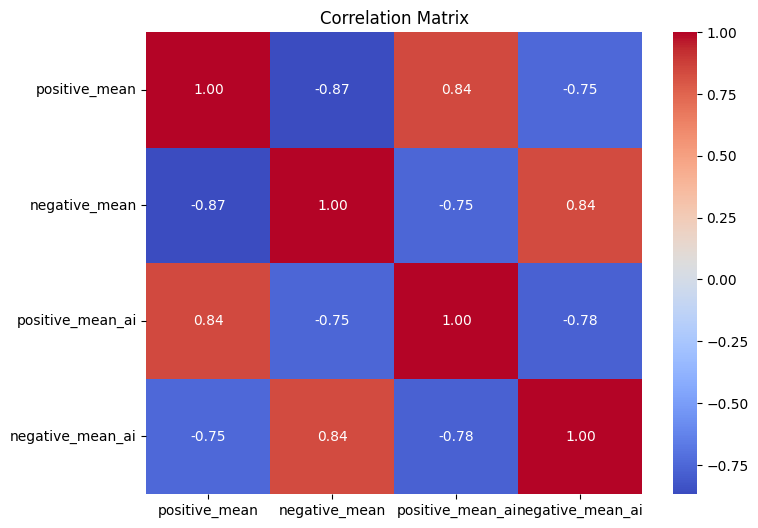

In [30]:
# select only columns that have pos in their name
df_num = data.filter(regex="mean").select_dtypes(include=["number"])

corr=df_num.corr(method="spearman") # method="kendall, spearman"

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()